# Earthquakes: success and failure cases, scalability

**Goal:** for the earthquake data, starting from the settings chosen in `08_usgs_earthquakes_2023_clustering.ipynb`:
show success and failure cases with their cause, measure runtime against data size, and compare with the other
datasets.

**Settings** (from `08_usgs_earthquakes_2023_clustering.ipynb`):
- K-means++: K=6, 10 starts, on unit vectors (section 2);
- DBSCAN: eps and `min_samples` from `results/earthquakes_2023/dbscan_grid.csv` with `tuning.best_setting_by_shared_rule` (section 4), haversine distance;
- HDBSCAN: `min_cluster_size` and `min_samples` from `results/earthquakes_2023/hdbscan_grid.csv` with `tuning.best_setting_by_shared_rule` (section 5), haversine distance.

Terms as in `08_usgs_earthquakes_2023_clustering.ipynb`.

**Seeds:** 0 for all model fits and the silhouette sample; 0 to 2 for the subsamples in the scalability test.

**Contents**
1. Data and settings
2. Success and failure cases
3. Scalability
4. Across datasets: comparison and key factors
5. Summary

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from sc4020 import methods, tuning
from sc4020.clusters import relabel_by_size
from sc4020.datasets import load_dataset
from sc4020.datasets.preprocess_dataset import (
    EARTH_RADIUS_KM,
    region_from_place,
    to_radians,
    to_unit_vectors,
)
from sc4020.metrics import (
    NOISE_LABEL,
    evaluate,
    haversine_km,
)
from sc4020.paths import REPO, results_dir

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)
SEED = 0
SILHOUETTE_SAMPLE = 5000
RESULTS = results_dir("earthquakes_2023")
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)
# tab10 without its grey (index 7), so no cluster is drawn in the same colour as noise
PALETTE = [colour for index, colour in enumerate(plt.cm.tab10.colors) if index != 7]


def cluster_colours(labels):
    return [PALETTE[label % len(PALETTE)] for label in labels]


def shifted_longitude(lon):
    """Longitude on 0 to 360, so the area around the 180 degree line is drawn in one piece."""
    return np.mod(lon, 360)

## 1. Data and settings

In [2]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    events = load_dataset("earthquakes_2023").events
for warning in caught:
    print("warning:", warning.message)
degrees = events[["latitude", "longitude"]].to_numpy()
R, U = (
    to_radians(degrees[:, 0], degrees[:, 1]),
    to_unit_vectors(degrees[:, 0], degrees[:, 1]),
)

# K, eps and min_cluster_size as chosen in earthquakes_2023_clustering, re-picked from its saved tables
k_selection = pd.read_csv(RESULTS / "kmeans_k_selection.csv")
CHOSEN_K, _ = tuning.stable_k_with_largest_null_gap(
    k_selection["K"],
    k_selection["silhouette_minus_null"],
    k_selection["seed_stability_min_ari"],
)
best_dbscan = tuning.best_setting_by_shared_rule(
    pd.read_csv(RESULTS / "dbscan_grid.csv")
)
best_hdbscan = tuning.best_setting_by_shared_rule(
    pd.read_csv(RESULTS / "hdbscan_grid.csv")
)
EPS_KM, MIN_SAMPLES = float(best_dbscan["eps_km"]), int(best_dbscan["min_samples"])
MIN_CLUSTER_SIZE = int(best_hdbscan["min_cluster_size"])
HDBSCAN_MIN_SAMPLES = (
    None
    if str(best_hdbscan["min_samples"]) == "default"
    else int(best_hdbscan["min_samples"])
)


def fit_baseline(deg):
    """Baseline labels of the three method families on [latitude, longitude] degrees."""
    Rd, Ud = to_radians(deg[:, 0], deg[:, 1]), to_unit_vectors(deg[:, 0], deg[:, 1])
    return {
        "K-means++": methods.kmeans(CHOSEN_K, n_init=10, random_state=SEED).fit_predict(
            Ud
        ),
        "DBSCAN": methods.dbscan(
            EPS_KM / EARTH_RADIUS_KM, MIN_SAMPLES, metric="haversine"
        ).fit_predict(Rd),
        "HDBSCAN": methods.hdbscan(
            MIN_CLUSTER_SIZE, HDBSCAN_MIN_SAMPLES, metric="haversine"
        ).fit_predict(Rd),
    }


def scores(mask, labels):
    """evaluate() on the earthquakes selected by a boolean mask."""
    return evaluate(
        R[mask],
        labels,
        silhouette_sample=SILHOUETTE_SAMPLE,
        seed=SEED,
        metric="haversine",
        X_davies_bouldin=U[mask],
    )


baseline = fit_baseline(degrees)
everything = np.ones(len(events), dtype=bool)
pd.DataFrame(
    {
        method: {"setting": setting, **scores(everything, baseline[method])}
        for method, setting in {
            "K-means++": f"K={CHOSEN_K}, n_init=10",
            "DBSCAN": f"eps={EPS_KM:.1f} km, min_samples={MIN_SAMPLES}",
            "HDBSCAN": f"min_cluster_size={MIN_CLUSTER_SIZE}, min_samples={best_hdbscan['min_samples']}",
        }.items()
    }
).T

,setting,n_clusters,noise_fraction,largest_cluster_share,silhouette,davies_bouldin,calinski_harabasz
K-means++,"K=6, n_init=10",6,0.0,0.31,0.529,0.738,7584.157
DBSCAN,"eps=101.8 km, min_samples=20",41,0.404,0.118,0.703,0.351,62580.505
HDBSCAN,"min_cluster_size=50, min_samples=default",28,0.307,0.075,0.758,0.329,22962.541


## 2. Success and failure cases

**Density (DBSCAN vs HDBSCAN).** Two areas with different density: the Americas (sparse, long belts) and
the south-west Pacific from the Solomon Islands to Tonga (very dense). Baseline labels from section 1.

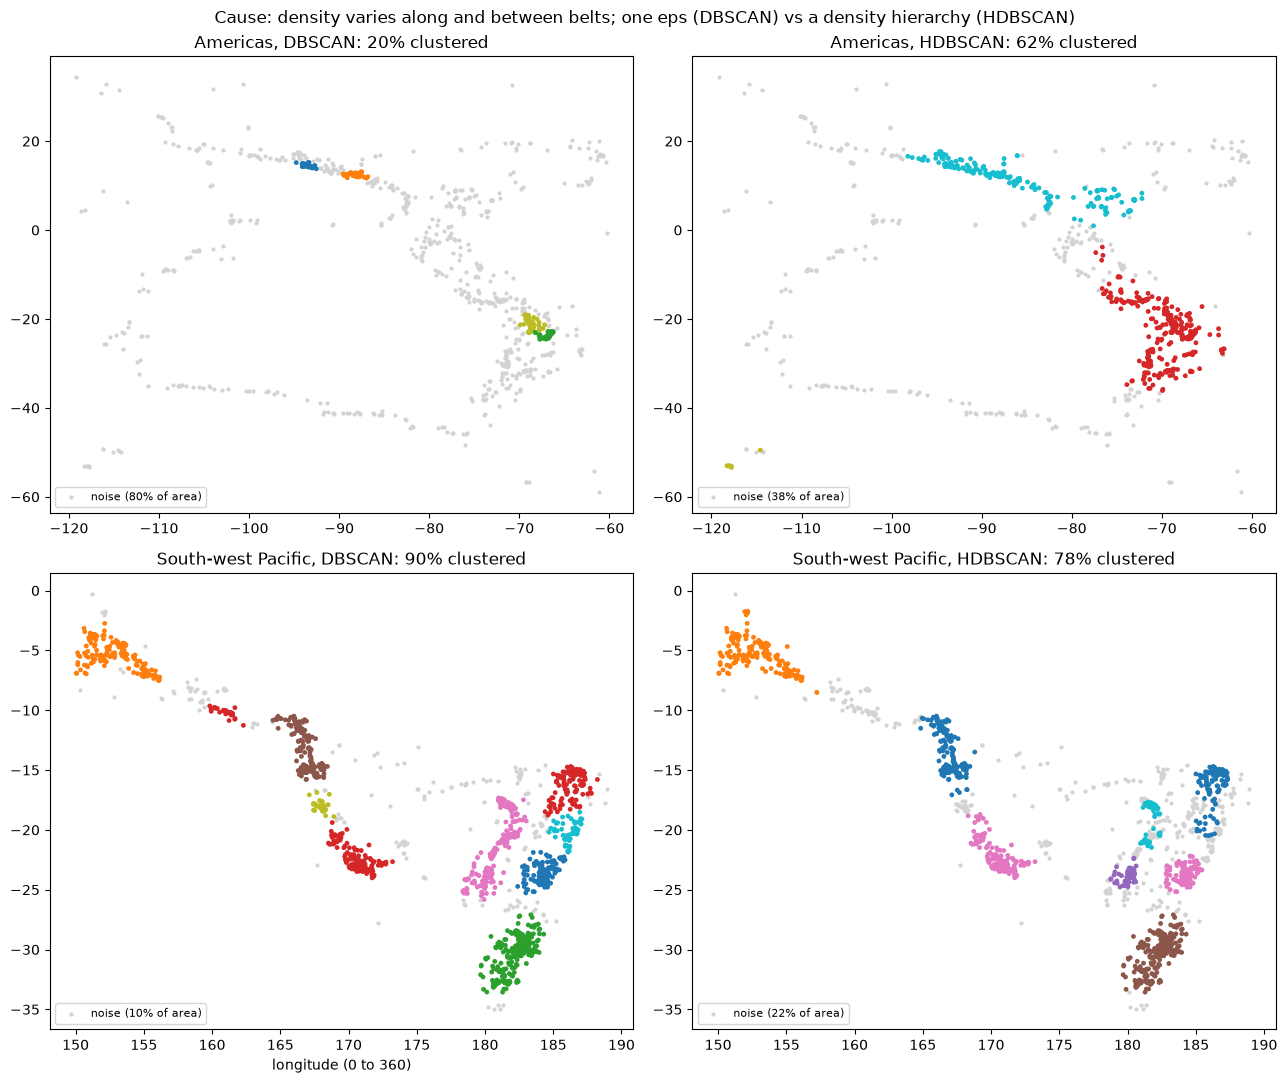

,region,method,n_earthquakes,clustered_fraction
0,Americas,DBSCAN,863,0.204
1,Americas,HDBSCAN,863,0.625
2,South-west Pacific,DBSCAN,1806,0.900
3,South-west Pacific,HDBSCAN,1806,0.776


In [3]:
from sc4020.generate_figures import show_and_save_to


def draw(ax, mask, labels, title, shift=False):
    lon = events.loc[mask, "longitude"].to_numpy()
    x = shifted_longitude(lon) if shift else lon
    y = events.loc[mask, "latitude"].to_numpy()
    part = labels[mask]
    noise = part == NOISE_LABEL
    ax.scatter(
        x[noise],
        y[noise],
        s=4,
        color="lightgrey",
        label=f"noise ({noise.mean():.0%} of area)",
    )
    ax.scatter(x[~noise], y[~noise], s=6, color=cluster_colours(part[~noise]))
    ax.set(title=title)
    ax.legend(loc="lower left", fontsize=8)


lat, lon = events["latitude"], events["longitude"]
americas = (lon.between(-120, -60) & lat.between(-60, 35)).to_numpy()
southwest_pacific = (
    lat.between(-35, 0) & shifted_longitude(lon).between(150, 190)
).to_numpy()
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for col, method in enumerate(["DBSCAN", "HDBSCAN"]):
    labels = relabel_by_size(baseline[method])
    draw(
        axes[0, col],
        americas,
        labels,
        f"Americas, {method}: {(labels[americas] != NOISE_LABEL).mean():.0%} clustered",
    )
    draw(
        axes[1, col],
        southwest_pacific,
        labels,
        f"South-west Pacific, {method}: {(labels[southwest_pacific] != NOISE_LABEL).mean():.0%} clustered",
        shift=True,
    )
axes[1, 0].set(xlabel="longitude (0 to 360)")
fig.suptitle(
    "Cause: density varies along and between belts; one eps (DBSCAN) vs a density hierarchy (HDBSCAN)"
)
plt.tight_layout()
show_and_save_to(fig, FIGURES / "case_density_dbscan_vs_hdbscan.png")

regions = {"Americas": americas, "South-west Pacific": southwest_pacific}
density_regions = pd.DataFrame(
    [
        {
            "region": region,
            "method": method,
            "n_earthquakes": int(mask.sum()),
            "clustered_fraction": float((baseline[method][mask] != NOISE_LABEL).mean()),
        }
        for region, mask in regions.items()
        for method in ["DBSCAN", "HDBSCAN"]
    ]
)
density_regions.to_csv(RESULTS / "case_density_regions.csv", index=False)
density_regions

**Shape (K-means).** K-means assumes compact, roughly round clusters around a centre. The K-means
cluster containing Turkey is drawn with the HDBSCAN clusters inside it, and the distances between the
centres of those HDBSCAN clusters are measured.

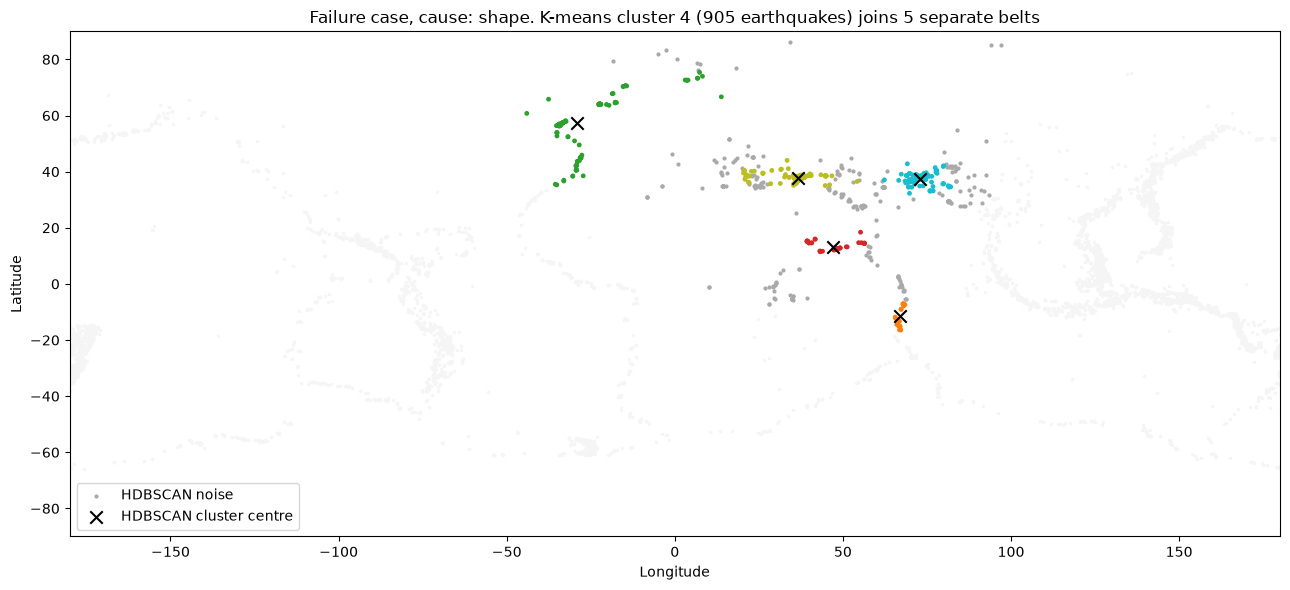

distance between HDBSCAN cluster centres inside K-means cluster 4: min 2932 km, max 11449 km


,events,centre latitude,centre longitude,median km to centre,top regions
0,246,37.914,36.506,129.532,"Turkey (184), Central Turkey (17), Greece (12)"
1,183,57.237,-29.176,830.585,"Reykjanes Ridge (86), Iceland (44), northern Mid-Atlantic Ridge (24)"
2,113,37.314,73.037,239.368,"Afghanistan (39), Tajikistan (34), China (19)"
3,28,-11.454,67.032,399.812,"Mid-Indian Ridge (23), Chagos Archipelago region (5)"
4,67,13.310,47.177,152.998,"Somalia (40), Eritrea (9), Owen Fracture Zone region (5)"


In [4]:
from sc4020.generate_figures import cluster_summary, show_and_save_to

kmeans_labels = relabel_by_size(baseline["K-means++"])
hdbscan_labels = relabel_by_size(baseline["HDBSCAN"])
regions = region_from_place(events["place"])
turkey_cluster = int(
    pd.Series(kmeans_labels[(regions == "Turkey").to_numpy()]).mode()[0]
)
inside = kmeans_labels == turkey_cluster

fig, ax = plt.subplots(figsize=(13, 6))
ax.scatter(lon[~inside], lat[~inside], s=2, color="whitesmoke")
noise = inside & (hdbscan_labels == NOISE_LABEL)
ax.scatter(lon[noise], lat[noise], s=4, color="darkgrey", label="HDBSCAN noise")
kept = inside & (hdbscan_labels != NOISE_LABEL)
ax.scatter(lon[kept], lat[kept], s=6, color=cluster_colours(hdbscan_labels[kept]))
summary = cluster_summary(events[inside].reset_index(drop=True), hdbscan_labels[inside])
summary = summary[summary["events"] >= 10]
ax.scatter(
    summary["centre longitude"],
    summary["centre latitude"],
    marker="x",
    s=80,
    color="black",
    label="HDBSCAN cluster centre",
)
ax.set(
    xlim=(-180, 180),
    ylim=(-90, 90),
    xlabel="Longitude",
    ylabel="Latitude",
    title=f"Failure case, cause: shape. K-means cluster {turkey_cluster} ({inside.sum()} earthquakes) joins {len(summary)} separate belts",
)
ax.legend(loc="lower left")
plt.tight_layout()
show_and_save_to(fig, FIGURES / "case_kmeans_merges_belts.png")

centres = summary[["centre latitude", "centre longitude"]].to_numpy()
gaps = haversine_km(
    centres[:, None, 0], centres[:, None, 1], centres[None, :, 0], centres[None, :, 1]
)
print(
    f"distance between HDBSCAN cluster centres inside K-means cluster {turkey_cluster}: "
    f"min {gaps[np.triu_indices(len(centres), 1)].min():.0f} km, max {gaps.max():.0f} km"
)
summary[
    [
        "events",
        "centre latitude",
        "centre longitude",
        "median km to centre",
        "top regions",
    ]
]

**Observations**

**Density, DBSCAN vs HDBSCAN** (baseline settings):
- **Americas: success for HDBSCAN, failure for DBSCAN.** HDBSCAN clusters 62% of the area's earthquakes and keeps the Mexico to Panama belt and the Chile and Argentina belt as long clusters. DBSCAN clusters 20%: four short segments, with the rest as noise.
- **South-west Pacific: DBSCAN clusters more.** DBSCAN clusters 90% of the area and splits it into compact groups along each arc; HDBSCAN clusters 78% and leaves the earthquakes between its dense cores as noise.
- **Cause: density varies between belts.** An eps of 101.8 km suits the dense arcs of the western Pacific but not the sparser belts of the Americas; HDBSCAN picks a density level per cluster, which recovers the sparse belts but trims the edges of very dense cores.

**Shape, K-means:**
- **Failure.** K-means cluster 4 (905 earthquakes) contains 5 HDBSCAN clusters of at least 10 earthquakes: Turkey (246), the Reykjanes Ridge and Iceland (183), Afghanistan and Tajikistan (113), Somalia and Eritrea (67) and the Mid-Indian Ridge (28). Their centres are 2,932 to 11,449 km apart, and most of the cluster's other earthquakes are HDBSCAN noise.
- **Cause: shape.** K-means assigns each earthquake to the nearest of 6 centres, so it assumes compact groups around a centre. Earthquakes lie on long, thin belts with empty space between them, and K-means joins whatever belts share a nearest centre, however large the gaps.


## 3. Scalability

Runtime against the number of earthquakes: random subsets of 500, 1,000, 2,000 and 4,000 earthquakes and
the full 7,643, three subsets per size (seeds 0 to 2), baseline settings. One untimed warm-up fit of each
method runs first. The slope of log(seconds) against log(n) estimates how runtime grows (1 = linear, 2 = quadratic).
Runtimes vary between runs; the slopes and the ordering are the result, not the exact seconds.

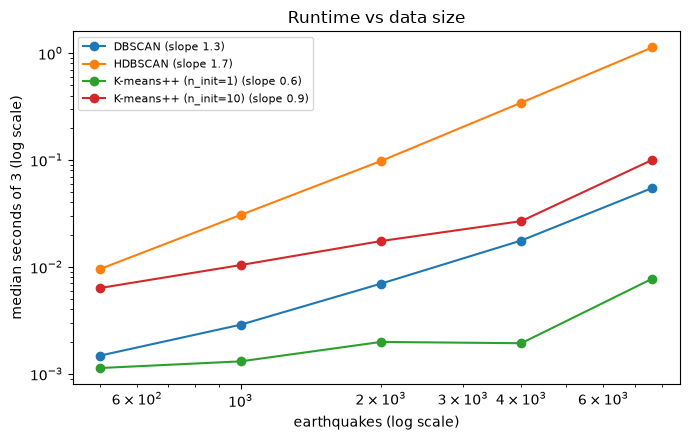

method,DBSCAN,HDBSCAN,K-means++ (n_init=1),K-means++ (n_init=10)
n,,,,
500,0.001,0.010,0.001,0.006
1000,0.003,0.031,0.001,0.010
2000,0.007,0.098,0.002,0.017
4000,0.018,0.344,0.002,0.027
7643,0.055,1.130,0.008,0.100


,log-log slope
DBSCAN,1.319
HDBSCAN,1.749
K-means++ (n_init=1),0.616
K-means++ (n_init=10),0.942


In [5]:
from sc4020.generate_figures import show_and_save_to

timed_methods = {
    "K-means++ (n_init=10)": (
        lambda: methods.kmeans(CHOSEN_K, n_init=10, random_state=SEED),
        U,
    ),
    "K-means++ (n_init=1)": (
        lambda: methods.kmeans(CHOSEN_K, n_init=1, random_state=SEED),
        U,
    ),
    "DBSCAN": (
        lambda: methods.dbscan(
            EPS_KM / EARTH_RADIUS_KM, MIN_SAMPLES, metric="haversine"
        ),
        R,
    ),
    "HDBSCAN": (
        lambda: methods.hdbscan(
            MIN_CLUSTER_SIZE, HDBSCAN_MIN_SAMPLES, metric="haversine"
        ),
        R,
    ),
}
for make, X in timed_methods.values():
    make().fit_predict(X[:1000])

SIZES = (500, 1000, 2000, 4000, len(events))
rows = []
for n in SIZES:
    for seed in range(3):
        subset = np.random.default_rng(seed).choice(len(events), n, replace=False)
        for method, (make, X) in timed_methods.items():
            _, seconds = methods.fit_predict_timed(make(), X[subset])
            rows.append({"n": n, "seed": seed, "method": method, "seconds": seconds})
scaling = pd.DataFrame(rows)
scaling.to_csv(RESULTS / "scalability.csv", index=False)

median_seconds = scaling.groupby(["method", "n"])["seconds"].median().unstack("method")
slopes = {
    method: np.polyfit(np.log(median_seconds.index), np.log(median_seconds[method]), 1)[
        0
    ]
    for method in median_seconds
}
fig, ax = plt.subplots(figsize=(7, 4.5))
for method in median_seconds:
    ax.plot(
        median_seconds.index,
        median_seconds[method],
        marker="o",
        label=f"{method} (slope {slopes[method]:.1f})",
    )
ax.set(
    xscale="log",
    yscale="log",
    xlabel="earthquakes (log scale)",
    ylabel="median seconds of 3 (log scale)",
    title="Runtime vs data size",
)
ax.legend(fontsize=8)
plt.tight_layout()
show_and_save_to(fig, FIGURES / "scalability.png")
display(median_seconds)
pd.Series(slopes, name="log-log slope").to_frame()

**Observations**

- **HDBSCAN is the slowest at every size**: 1.13 s on all 7,643 earthquakes, about 20 times DBSCAN (0.055 s). Its runtime grows fastest (log-log slope 1.75), so 10 times more earthquakes would take about 55 times longer.
- **DBSCAN grows faster than linearly** (slope 1.32). Its eps is fixed in km, so with more earthquakes each neighbourhood holds more points to check.
- **K-means++ shows slopes below 1** (0.62 with one start, 0.94 with 10). At these sizes a fixed cost per fit dominates, so this range does not show how it grows on larger data.
- **At 7,643 earthquakes every method takes about a second or less**, so runtime does not decide between them on this dataset.

## 4. Across datasets: comparison and key factors

The other datasets are analysed in `../sc4020-clustering`. Their result CSVs are read here if present.
Caveats: earthquake silhouette uses great-circle distance, LTA silhouette uses Euclidean distance on
usage profiles, so silhouette values are comparable within a dataset, not across datasets. The synthetic
comparison uses fixed settings (DBSCAN eps 0.3, HDBSCAN `min_cluster_size` 15), not tuned ones.

In [6]:
OTHER = (
    REPO.parent / "sc4020-clustering" / "results"
)  # a separate project, outside this repo
columns = [
    "dataset",
    "method",
    "params",
    "n_clusters",
    "noise_fraction",
    "largest_cluster_share",
    "silhouette",
    "null_silhouette",
    "davies_bouldin",
    "fit_seconds",
]
frames = [pd.read_csv(RESULTS / "method_comparison.csv").assign(dataset="earthquakes")]
lta_path = OTHER / "lta" / "method_comparison.csv"
if lta_path.exists():
    lta = pd.read_csv(lta_path).rename(
        columns={
            "silhouette_null": "null_silhouette",
            "setting": "params",
            "seconds": "fit_seconds",
        }
    )
    frames.append(lta.assign(dataset="LTA " + lta["kind"].str.lower()))
else:
    print(f"not found: {lta_path}")
cross_dataset = pd.concat(frames, ignore_index=True)[columns]
cross_dataset.to_csv(RESULTS / "cross_dataset_comparison.csv", index=False)
display(cross_dataset)

synthetic_path = OTHER / "synthetic" / "synthetic_comparison.csv"
if synthetic_path.exists():
    display(
        Markdown("**Synthetic datasets: ARI against the true labels** (fixed settings)")
    )
    display(
        pd.read_csv(synthetic_path).pivot(
            index="dataset", columns="method", values="ari"
        )
    )
else:
    print(f"not found: {synthetic_path}")

,dataset,method,params,n_clusters,noise_fraction,largest_cluster_share,silhouette,null_silhouette,davies_bouldin,fit_seconds
0,earthquakes,K-means++,"K=6, n_init=1",6.0,0.000,0.310,0.529,0.390,0.738,5.649e-03
1,earthquakes,DBSCAN,"eps=101.8 km, min_samples=20",41.0,0.404,0.118,0.703,NaN,0.351,5.210e-02
2,earthquakes,HDBSCAN,"min_cluster_size=50, min_samples=default",28.0,0.307,0.075,0.758,0.320,0.329,1.089e+00
3,earthquakes,GMM,"n_components=12, covariance_type=full",12.0,0.000,0.167,0.442,0.352,0.907,4.058e-01
4,earthquakes,Spectral,"K=6, affinity=nearest_neighbors",6.0,0.000,0.316,0.333,0.320,0.914,8.938e-02
5,LTA train,K-means (random),"K=4, n_init=1",4.0,0.000,0.486,0.260,0.067,1.313,1.539e-03
6,LTA train,K-means++,"K=4, n_init=1",4.0,0.000,0.481,0.257,0.066,1.332,7.653e-04
7,LTA train,DBSCAN,"eps=0.0686 (p75), min_samples=5",2.0,0.135,0.816,0.487,NaN,0.595,1.226e-03
8,LTA train,HDBSCAN,"min_cluster_size=5, min_samples=default",2.0,0.416,0.551,0.497,NaN,0.533,3.156e-03
9,LTA bus,K-means (random),"K=5, n_init=1",5.0,0.000,0.299,0.204,0.082,1.483,1.490e-02


**Synthetic datasets: ARI against the true labels** (fixed settings)

method,DBSCAN,HDBSCAN,K-means (random),K-means++
dataset,,,,
anisotropic,0.000e+00,0.972,8.957e-01,8.975e-01
blobs,1.608e-05,0.417,8.146e-01,8.146e-01
circles,1.000e+00,1.000,-6.676e-04,-6.515e-04
moons,1.000e+00,1.000,4.934e-01,4.934e-01
varied_density,1.524e-02,0.755,7.149e-01,7.149e-01


**Observations**

- **Density methods work only where screening found density structure.**
  - Earthquakes (Stage 0: HDBSCAN noise 22.7% vs 59% to 66% for the null): DBSCAN and HDBSCAN find 41 and 28 clusters, with 40.4% and 30.7% noise and no cluster above 11.8% of earthquakes.
  - LTA train (Stage 0: HDBSCAN 42% noise, from `../AGENTS.md`): both find only 2 clusters, with one holding 81.6% (DBSCAN) or 55.1% (HDBSCAN) of stations.
  - LTA bus (Stage 0: HDBSCAN 100% noise): HDBSCAN has no setting with 2 or more clusters and at most 50% noise; DBSCAN's one valid setting has 2 clusters, one holding 79.5% of stops.
- **K-means beats its null on every dataset:** silhouette 0.529 vs 0.390 (earthquakes), 0.257 vs 0.066 (LTA train) and 0.204 vs 0.133 (LTA bus, K-means++). It is the only method that describes every station in the LTA data.
- **Synthetic data (true labels, fixed settings):**
  - K-means fails on non-convex shapes: ARI about 0 on circles and 0.493 on moons, but 0.815 on blobs and 0.896 to 0.898 on anisotropic blobs;
  - HDBSCAN reaches 1.000 on moons and circles, 0.972 on anisotropic blobs and 0.755 on varied density, but only 0.417 on blobs;
  - DBSCAN with a fixed eps of 0.3 reaches 1.000 on moons and circles and about 0 on blobs, anisotropic blobs and varied density (0.015).
- **Key factors that change the ranking of methods:**
  1. **Gaps between dense groups** (the Stage 0 HDBSCAN test). With gaps (earthquakes, synthetic shapes) density methods find the structure; without them (LTA profiles) they collapse to one dominant cluster or no valid setting, and K-means is the useful method.
  2. **Shape.** Long or curved groups (earthquake belts, moons, circles) defeat K-means, which assumes compact groups around a centre.
  3. **Varying density.** One eps fails when density differs between groups (synthetic varied density: DBSCAN 0.015 vs HDBSCAN 0.755; Americas: 20% vs 62% clustered); HDBSCAN handles it better, at the cost of trimming dense cores.
- Silhouette values use different distances (great-circle for earthquakes, Euclidean for LTA), so they rank methods within a dataset, not datasets against each other.

## 5. Summary

| Item | Result | Evidence |
|---|---|---|
| Comparison and agreement | See `08_usgs_earthquakes_2023_clustering.ipynb` section 9; across datasets in section 4 here | `results/method_comparison.csv`, `results/method_agreement.csv`, `results/cross_dataset_comparison.csv` |
| Improvement: DBSCAN to HDBSCAN | HDBSCAN recovers sparse belts (Americas 62% vs 20% clustered) but trims dense cores (south-west Pacific 78% vs 90%) | `results/case_density_regions.csv`, `figures/case_density_dbscan_vs_hdbscan.png` |
| Failure case: shape | K-means cluster 4 joins 5 belts whose centres are 2,932 to 11,449 km apart | `figures/case_kmeans_merges_belts.png` |
| Scalability | HDBSCAN slowest (slope about 1.7 to 1.8), DBSCAN about 1.3 to 1.4; all methods about a second or less at 7,643 earthquakes | `results/scalability.csv`, `figures/scalability.png` |
| Key factors | Gaps between dense groups, cluster shape, varying density | Section 4 |